<a href="https://colab.research.google.com/github/leeknnn/viktoriiashkorubska-41/blob/master/lab_work_19/lab_work_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Спостережені дані ---
    місяць  температура  споживання_МВтгод
0        1         -3.7             5900.0
1        2         -2.9             5851.0
2        3          2.2             5692.0
3        4          9.0             5140.0
4        5         16.9             4779.0
5        6         20.5             4525.0
6        7         24.4             4384.0
7        8         21.2             4603.0
8        9         16.7             4716.0
9       10          9.4             5297.0
10      11          3.2             5619.0
11      12         -3.7             5966.0

--- Завдання 2: Побудова моделі ---
споживання ≈ 5739.1 + (-56.5) · температура

--- Завдання 3: Аналіз залишків та R² ---
    місяць  температура  споживання_МВтгод  передбачення    залишок
0        1         -3.7             5900.0   5948.249384 -48.249384
1        2         -2.9             5851.0   5903.036223 -52.036223
2        3          2.2             5692.0   5614.802326  77.197674
3        4         

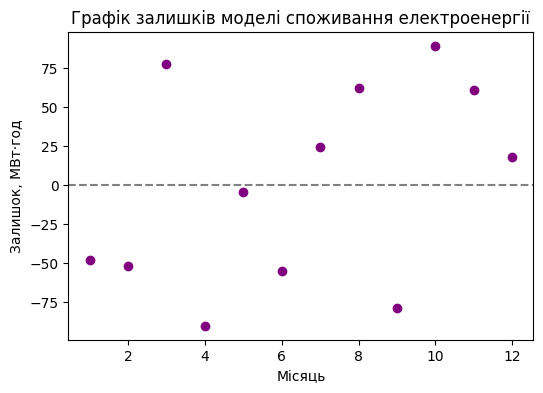

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Варіант 1: Київ
np.random.seed(1)
city = "Київ"
base_temp = 9.5
amplitude = 14
base_consumption = 5200
k = 55
noise_sd = 80

months = np.arange(1, 13)
temp = base_temp + amplitude * np.cos((months - 7) / 12 * 2 * np.pi)
temp = np.round(temp + np.random.normal(0, 0.5, size=12), 1)

consumption = base_consumption - k * (temp - base_temp) + np.random.normal(0, noise_sd, size=12)
consumption = np.round(consumption, 0)

city_data = pd.DataFrame({
    "місяць": months,
    "температура": temp,
    "споживання_МВтгод": consumption,
})

print("--- Спостережені дані ---")
print(city_data)

print("\n--- Завдання 2: Побудова моделі ---")
b, a = np.polyfit(city_data["температура"], city_data["споживання_МВтгод"], 1)
print(f"споживання ≈ {a:.1f} + ({b:.1f}) · температура")

city_data["передбачення"] = a + b * city_data["температура"]

print("\n--- Завдання 3: Аналіз залишків та R² ---")
city_data["залишок"] = city_data["споживання_МВтгод"] - city_data["передбачення"]
print(city_data[["місяць", "температура", "споживання_МВтгод", "передбачення", "залишок"]])

residuals = city_data["залишок"]
ss_res = (residuals ** 2).sum()
ss_tot = ((city_data["споживання_МВтгод"] - city_data["споживання_МВтгод"].mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot
print(f"\nКоефіцієнт детермінації R²: {r_squared:.4f}")

# Побудова графіка залишків
plt.figure(figsize=(6, 4))
plt.scatter(city_data["місяць"], residuals, color="purple")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Місяць")
plt.ylabel("Залишок, МВт·год")
plt.title("Графік залишків моделі споживання електроенергії")
plt.show()

## Відповіді на контрольні питання

1. **Як класифікується модель споживання за осями Лекції 19?**
   - **Стохастична:** базова залежність задана детермінованою формулою, але наявність випадкового випадкового шуму (змінна $\sigma$) робить модель стохастичною.
   - **Описова (прогнозна):** модель не є балансовою (не містить законів збереження), оптимізаційною (не шукає найкраще рішення) чи імітаційною (не відтворює покрокову динаміку процесу в часі), а слугує для статистичного зв'язку факторів.
   - **Статична:** прогноз для кожного місяця залежить виключно від температури поточного місяця, а не від попередніх станів системи.

2. **Чому знак коефіцієнта $b$ обов'язково від'ємний?**
   - Коефіцієнт $b$ відображає нахил залежності: при зниженні температури повітря (особливо нижче середньорічної) зростає потреба в опаленні та обігріві приміщень, що збільшує споживання електроенергії. Відповідно, між температурою та споживанням існує обернений зв'язок, що зумовлює від'ємний знак $b$.

3. **Що показує структура залишків у Завданні 3?**
   - Значення $R^2$ близько до одиниці свідчить про високу загальну частку поясненої дисперсії. Водночас аналіз графіка залишків дозволяє переконатися, чи залишки випадково й рівномірно розкидані навколо нульової лінії без систематичних патернів (дуг чи лійок), що підтверджує коректність лінійної специфікації.

4. **Як розмежовуються верифікація та валідація на практиці?**
   - **Верифікація** полягає у технічній перевірці правильності реалізації алгоритму (наприклад, порівнянні ручного підрахунку рівняння за формулою з результатами виконання коду). **Валідація** ж оцінює відповідність самої побудованої моделі реальному процесу та часто вимагає залучення нових незалежних даних, які не використовувались під час підбору параметрів моделі.